<a href="https://colab.research.google.com/github/EduardoKenzoHayashi/CN-Lobosco/blob/main/Integracao_Numerica_Aula_Calculo_Numerico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Integração Numérica — Cálculo Numérico

## Aula detalhada: aproximação de integrais definidas

**Objetivos de aprendizagem**


1. interpretar a integral definida como área acumulada;
2. aproximar integrais pelas regras do ponto médio, dos trapézios e de Simpson;
3. implementar essas regras em Python;
4. comparar aproximações com um valor de referência e interpretar erros;
5. usar refinamento de malha para avaliar a convergência.



### 1. Integral definida e interpretação geométrica

A integral definida

$$
I=\int_a^b f(x)\,dx
$$

permite calcular a **acumulação dos valores de uma função** entre os limites $a$ e $b$. Em muitas situações, essa acumulação pode ser interpretada como uma área.

Por exemplo, se $f(x)$ representa a velocidade de um objeto ao longo do tempo, a integral da velocidade em um intervalo de tempo fornece o deslocamento do objeto nesse período. Se $f(x)$ representa a vazão de um fluido, sua integral ao longo do tempo fornece o volume acumulado.

#### Interpretação como área

Quando o gráfico de $f(x)$ está acima do eixo horizontal, isto é, quando $f(x)\geq 0$, a integral corresponde à área entre o gráfico e o eixo $x$.

Quando o gráfico está abaixo do eixo $x$, a função assume valores negativos. Nesse caso, essa região contribui negativamente para a integral. Por isso, dizemos que a integral definida representa uma **área com sinal** ou uma **acumulação líquida**: as contribuições positivas e negativas são somadas levando em conta seus sinais.

> A integral definida não é necessariamente igual à área geométrica total. Se a função assume valores positivos e negativos, as regiões abaixo do eixo $x$ são subtraídas das regiões acima dele.

#### Divisão do intervalo

Em geral, não calculamos diretamente a área sob uma curva complexa. Em vez disso, dividimos o intervalo $[a,b]$ em partes menores e aproximamos a curva por formas geométricas mais simples.

Dividimos o intervalo em $n$ subintervalos de mesma largura. O comprimento de cada subintervalo, chamado de passo ou espaçamento, é

$$
h=\frac{b-a}{n}.
$$

Os pontos que delimitam os subintervalos são

$$
x_i=a+ih,\qquad i=0,1,\ldots,n.
$$

Assim, o intervalo $[a,b]$ fica dividido nos trechos

$$
[x_0,x_1],\ [x_1,x_2],\ \ldots,\ [x_{n-1},x_n].
$$

Por exemplo, se dividirmos $[0,1]$ em quatro subintervalos, teremos

$$
n=4,\qquad h=\frac{1-0}{4}=0{,}25,
$$

e os pontos serão

$$
x_0=0,\quad x_1=0{,}25,\quad x_2=0{,}50,\quad
x_3=0{,}75,\quad x_4=1.
$$

#### Aproximação numérica da integral

Em cada subintervalo, podemos aproximar a região sob a curva por uma figura simples:

- **retângulos**, usando valores da função em pontos escolhidos;
- **trapézios**, ligando pontos consecutivos do gráfico por segmentos de reta;
- **parábolas**, ajustadas a grupos de pontos, como na regra de Simpson.

A integral é então aproximada pela soma das áreas dessas figuras. Quanto menores forem os subintervalos, mais detalhada será a representação da curva e, em geral, melhor será a aproximação.

Entretanto, aumentar o número de subintervalos também exige mais avaliações da função e mais cálculos. Além disso, uma malha mais fina não elimina automaticamente dificuldades como descontinuidades, oscilações ou ruído em dados experimentais. Por isso, a escolha do método e do número de subintervalos deve levar em conta as características do problema.

In [182]:
import numpy as np
import matplotlib.pyplot as plt
from math import factorial

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["font.size"] = 11


## 2. Regra do ponto médio

A regra do ponto médio aproxima a área sob a curva usando retângulos. Em cada subintervalo, a altura do retângulo é determinada pelo valor da função no ponto central desse intervalo.

### Construção da aproximação

Dividimos o intervalo $[a,b]$ em $n$ subintervalos de mesma largura:

$$
h=\frac{b-a}{n}.
$$

Os pontos que delimitam esses subintervalos são

$$
x_i=a+ih,\qquad i=0,1,\ldots,n.
$$

No subintervalo $[x_i,x_{i+1}]$, o ponto médio é

$$
m_i=\frac{x_i+x_{i+1}}{2}
    =a+\left(i+\frac{1}{2}\right)h.
$$

A altura do retângulo nesse subintervalo é $f(m_i)$, e sua base tem comprimento $h$. Portanto, a área aproximada desse retângulo é

$$
A_i\approx h\,f(m_i).
$$

Somando as áreas dos $n$ retângulos, obtemos a regra composta do ponto médio:

$$
M_n
=
h\sum_{i=0}^{n-1}
f\left(a+\left(i+\frac{1}{2}\right)h\right).
$$

Essa soma fornece uma aproximação para a integral definida:

$$
\int_a^b f(x)\,dx\approx M_n.
$$

### Interpretação geométrica

Em cada subintervalo, usamos o valor da função no centro para representar a altura do retângulo. Assim, a curva é aproximada por uma sequência de retângulos, um para cada subintervalo.

Se a função for positiva, a soma das áreas dos retângulos aproxima a área sob o gráfico. Se a função assumir valores negativos, as alturas correspondentes também serão negativas e as áreas serão consideradas com sinal.

### Exemplo

Considere a função $f(x)=x^2$ no intervalo $[0,2]$, dividido em $n=2$ subintervalos.

A largura de cada subintervalo é

$$
h=\frac{2-0}{2}=1.
$$

Os subintervalos são $[0,1]$ e $[1,2]$, cujos pontos médios são

$$
m_0=0{,}5,\qquad m_1=1{,}5.
$$

Aplicando a regra do ponto médio:

$$
M_2
=
1\left[f(0{,}5)+f(1{,}5)\right].
$$

Como $f(x)=x^2$,

$$
M_2
=
(0{,}5)^2+(1{,}5)^2
=
0{,}25+2{,}25
=
2{,}5.
$$

Portanto,

$$
\int_0^2 x^2\,dx\approx 2{,}5.
$$

O valor exato da integral é

$$
\int_0^2 x^2\,dx
=
\left[\frac{x^3}{3}\right]_0^2
=
\frac{8}{3}
\approx 2{,}667.
$$

Neste caso, a aproximação obtida com dois subintervalos é próxima do valor exato, mas não coincide com ele.

### Precisão e erro

Para funções suficientemente suaves, isto é, com derivadas contínuas até segunda ordem, o erro global da regra do ponto médio é da ordem de $h^2$. Isso significa que, quando reduzimos a largura dos subintervalos pela metade, o erro tende a diminuir aproximadamente por um fator de quatro.

Por exemplo, se uma malha produz um erro de aproximadamente $0{,}04$, uma malha com o dobro de subintervalos pode produzir um erro próximo de $0{,}01$, desde que a função seja suave e a aproximação já esteja na faixa em que esse comportamento é observado.

Esse comportamento é uma tendência teórica, não uma garantia para qualquer função. Descontinuidades, oscilações e dados ruidosos podem alterar a precisão observada.

### Resumo

- Cada subintervalo tem largura $h$.
- A altura de cada retângulo é calculada no ponto médio do subintervalo.
- A aproximação é a soma das áreas dos retângulos.
- Para funções suaves, o erro global diminui aproximadamente com $h^2$.

In [183]:
def ponto_medio(f, a, b, n):
    """Aproxima integral de f em [a,b] pela regra composta do ponto médio."""
    if n < 1:
        raise ValueError("n deve ser um inteiro positivo")
    h = (b - a) / n
    x_meio = a + (np.arange(n) + 0.5) * h
    return h * np.sum(f(x_meio))

# Exemplo: integral de exp(-x^2) entre 0 e 1
f = lambda x: np.sin(x)
a, b, n = 0.0, 3.14, 2
print("Aproximação pelo ponto médio:", ponto_medio(f, a, b, n))


Aproximação pelo ponto médio: 2.2211984609134627


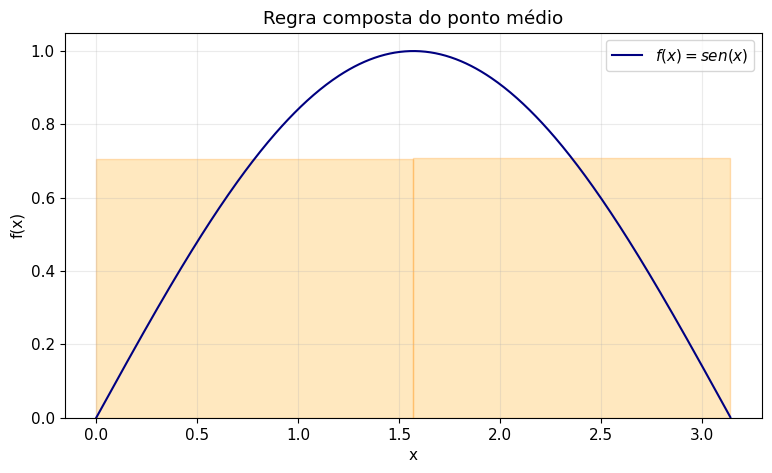

In [184]:
# Visualização dos retângulos do ponto médio
x = np.linspace(a, b, 500)
h = (b-a)/n
fig, ax = plt.subplots()
ax.plot(x, f(x), color="navy", label=r"$f(x)=sen(x)$")
for i in range(n):
    left = a + i*h
    mid = left + h/2
    ax.bar(mid, f(mid), width=h, align="center", alpha=0.25,
           edgecolor="darkorange", color="orange")
ax.set(xlabel="x", ylabel="f(x)", title="Regra composta do ponto médio")
ax.legend(); ax.grid(alpha=0.25); plt.show()


In [185]:
def trapezios(f, a, b, n):
    """Aproxima integral de f em [a,b] pela regra composta dos trapézios."""
    if n < 1:
        raise ValueError("n deve ser um inteiro positivo")
    x = np.linspace(a, b, n + 1)
    y = f(x)
    h = (b - a) / n
    return h * (0.5*y[0] + np.sum(y[1:-1]) + 0.5*y[-1])

print("Trapézios:", trapezios(f, a, b, n))


Trapézios: 1.5712497347424226


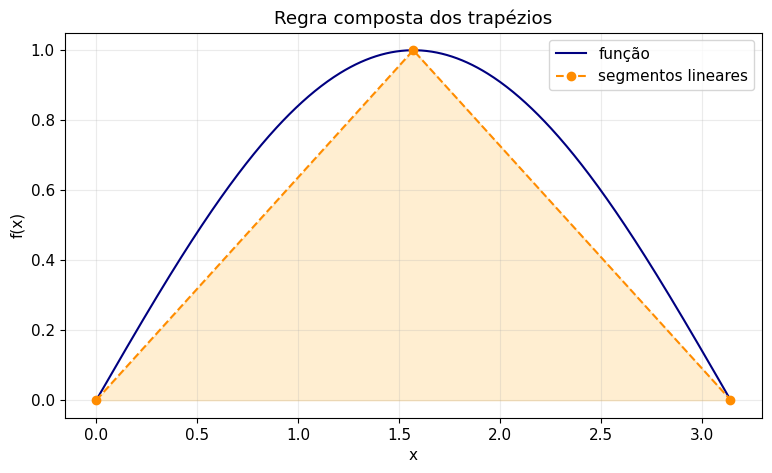

In [186]:
# Segmentos lineares usados pelos trapézios
x = np.linspace(a, b, 500)
xi = np.linspace(a, b, n+1)
fig, ax = plt.subplots()
ax.plot(x, f(x), color="navy", label="função")
ax.plot(xi, f(xi), "o--", color="darkorange", label="segmentos lineares")
ax.fill_between(xi, f(xi), alpha=0.18, color="orange")
ax.set(xlabel="x", ylabel="f(x)", title="Regra composta dos trapézios")
ax.legend(); ax.grid(alpha=0.25); plt.show()



In [187]:
def simpson(f, a, b, n):
    """Aproxima integral pela regra composta de Simpson 1/3 (n par)."""
    if n < 2 or n % 2 != 0:
        raise ValueError("Simpson 1/3 requer n par e n >= 2")
    x = np.linspace(a, b, n + 1)
    y = f(x)
    h = (b - a) / n
    return (h/3) * (y[0] + y[-1]
                    + 4*np.sum(y[1:-1:2])
                    + 2*np.sum(y[2:-1:2]))

print("Simpson:", simpson(f, a, b, n))


Simpson: 2.094166157963602


In [188]:
from scipy.integrate import quad

I_ref, erro_quad = quad(lambda x: np.exp(-x**2), 0, 1)
print(f"Referência (quad): {I_ref:.12f}")
print(f"Estimativa de erro do quad: {erro_quad:.2e}")

linhas = []
for n in [2, 4, 8, 16, 32, 64]:
    vals = {
        "n": n,
        "Ponto médio": ponto_medio(f, 0, 1, n),
        "Trapézios": trapezios(f, 0, 1, n),
        "Simpson": simpson(f, 0, 1, n),
    }
    for regra in ["Ponto médio", "Trapézios", "Simpson"]:
        vals["Erro " + regra] = abs(vals[regra] - I_ref)
    linhas.append(vals)

import pandas as pd
pd.DataFrame(linhas).set_index("n").style.format("{:.3e}")


Referência (quad): 0.746824132812
Estimativa de erro do quad: 8.29e-15


,Ponto médio,Trapézios,Simpson,Erro Ponto médio,Erro Trapézios,Erro Simpson
n,,,,,,
2,4.645e-01,4.501e-01,4.599e-01,2.823e-01,2.967e-01,2.870e-01
4,4.609e-01,4.573e-01,4.597e-01,2.859e-01,2.895e-01,2.871e-01
8,4.600e-01,4.591e-01,4.597e-01,2.868e-01,2.877e-01,2.871e-01
16,4.598e-01,4.595e-01,4.597e-01,2.871e-01,2.873e-01,2.871e-01
32,4.597e-01,4.597e-01,4.597e-01,2.871e-01,2.872e-01,2.871e-01
64,4.597e-01,4.597e-01,4.597e-01,2.871e-01,2.871e-01,2.871e-01


In [189]:
def ponto_medio(f, a, b, n):
    """Aproxima integral de f em [a,b] pela regra composta do ponto médio."""
    if n < 1:
        raise ValueError("n deve ser um inteiro positivo")
    h = (b - a) / n
    x_meio = a + (np.arange(n) + 0.5) * h
    return h * np.sum(f(x_meio))

# Exemplo: integral de exp(-x^2) entre 0 e 1
f = lambda x: np.sin(x)
a, b, n = 0.0, 3.14, 4
print("Aproximação pelo ponto médio:", ponto_medio(f, a, b, n))


Aproximação pelo ponto médio: 2.052288977615591


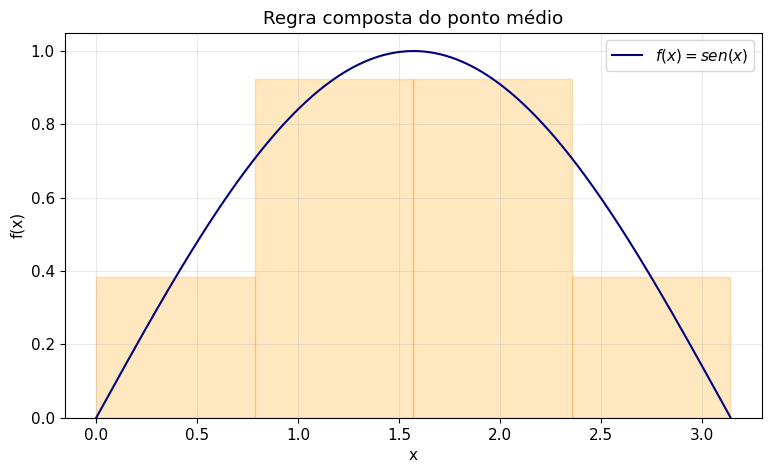

In [190]:
# Visualização dos retângulos do ponto médio
x = np.linspace(a, b, 500)
h = (b-a)/n
fig, ax = plt.subplots()
ax.plot(x, f(x), color="navy", label=r"$f(x)=sen(x)$")
for i in range(n):
    left = a + i*h
    mid = left + h/2
    ax.bar(mid, f(mid), width=h, align="center", alpha=0.25,
           edgecolor="darkorange", color="orange")
ax.set(xlabel="x", ylabel="f(x)", title="Regra composta do ponto médio")
ax.legend(); ax.grid(alpha=0.25); plt.show()



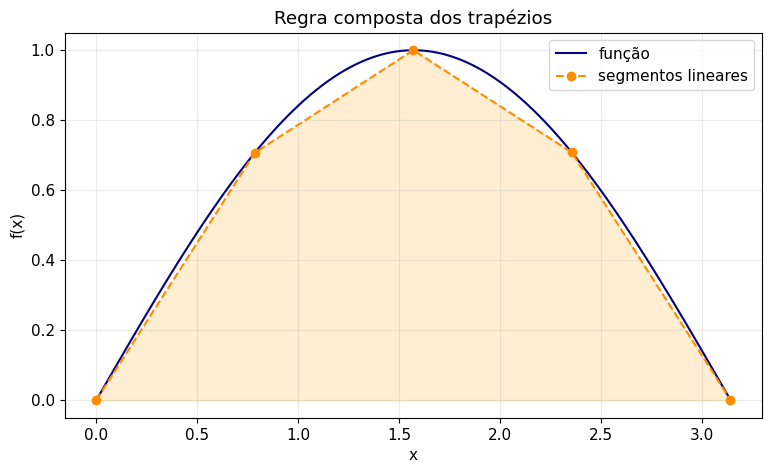

In [191]:
# Segmentos lineares usados pelos trapézios
x = np.linspace(a, b, 500)
xi = np.linspace(a, b, n+1)
fig, ax = plt.subplots()
ax.plot(x, f(x), color="navy", label="função")
ax.plot(xi, f(xi), "o--", color="darkorange", label="segmentos lineares")
ax.fill_between(xi, f(xi), alpha=0.18, color="orange")
ax.set(xlabel="x", ylabel="f(x)", title="Regra composta dos trapézios")
ax.legend(); ax.grid(alpha=0.25); plt.show()


In [192]:
def trapezios(f, a, b, n):
    """Aproxima integral de f em [a,b] pela regra composta dos trapézios."""
    if n < 1:
        raise ValueError("n deve ser um inteiro positivo")
    x = np.linspace(a, b, n + 1)
    y = f(x)
    h = (b - a) / n
    return h * (0.5*y[0] + np.sum(y[1:-1]) + 0.5*y[-1])

print("Trapézios:", trapezios(f, a, b, n))


Trapézios: 1.8962240978279425


In [193]:
def simpson(f, a, b, n):
    """Aproxima integral pela regra composta de Simpson 1/3 (n par)."""
    if n < 2 or n % 2 != 0:
        raise ValueError("Simpson 1/3 requer n par e n >= 2")
    x = np.linspace(a, b, n + 1)
    y = f(x)
    h = (b - a) / n
    return (h/3) * (y[0] + y[-1]
                    + 4*np.sum(y[1:-1:2])
                    + 2*np.sum(y[2:-1:2]))

print("Simpson:", simpson(f, a, b, n))



Simpson: 2.004548885523116


In [194]:
from scipy.integrate import quad

I_ref, erro_quad = quad(lambda x: np.exp(-x**2), 0, 1)
print(f"Referência (quad): {I_ref:.12f}")
print(f"Estimativa de erro do quad: {erro_quad:.2e}")

linhas = []
for n in [2, 4, 8, 16, 32, 64]:
    vals = {
        "n": n,
        "Ponto médio": ponto_medio(f, 0, 1, n),
        "Trapézios": trapezios(f, 0, 1, n),
        "Simpson": simpson(f, 0, 1, n),
    }
    for regra in ["Ponto médio", "Trapézios", "Simpson"]:
        vals["Erro " + regra] = abs(vals[regra] - I_ref)
    linhas.append(vals)

import pandas as pd
pd.DataFrame(linhas).set_index("n").style.format("{:.3e}")


Referência (quad): 0.746824132812
Estimativa de erro do quad: 8.29e-15


,Ponto médio,Trapézios,Simpson,Erro Ponto médio,Erro Trapézios,Erro Simpson
n,,,,,,
2,4.645e-01,4.501e-01,4.599e-01,2.823e-01,2.967e-01,2.870e-01
4,4.609e-01,4.573e-01,4.597e-01,2.859e-01,2.895e-01,2.871e-01
8,4.600e-01,4.591e-01,4.597e-01,2.868e-01,2.877e-01,2.871e-01
16,4.598e-01,4.595e-01,4.597e-01,2.871e-01,2.873e-01,2.871e-01
32,4.597e-01,4.597e-01,4.597e-01,2.871e-01,2.872e-01,2.871e-01
64,4.597e-01,4.597e-01,4.597e-01,2.871e-01,2.871e-01,2.871e-01


In [195]:
def ponto_medio(f, a, b, n):
    """Aproxima integral de f em [a,b] pela regra composta do ponto médio."""
    if n < 1:
        raise ValueError("n deve ser um inteiro positivo")
    h = (b - a) / n
    x_meio = a + (np.arange(n) + 0.5) * h
    return h * np.sum(f(x_meio))

# Exemplo: integral de exp(-x^2) entre 0 e 1
f = lambda x: np.sin(x)
a, b, n = 0.0, 3.14, 8
print("Aproximação pelo ponto médio:", ponto_medio(f, a, b, n))


Aproximação pelo ponto médio: 2.012894664743265


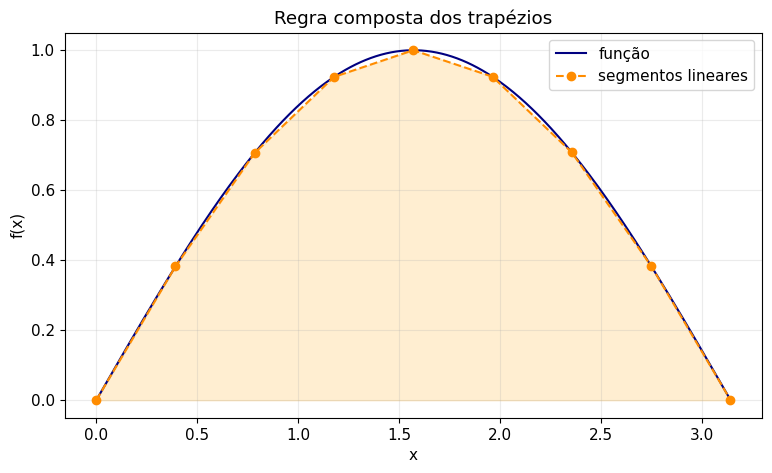

In [196]:
# Segmentos lineares usados pelos trapézios
x = np.linspace(a, b, 500)
xi = np.linspace(a, b, n+1)
fig, ax = plt.subplots()
ax.plot(x, f(x), color="navy", label="função")
ax.plot(xi, f(xi), "o--", color="darkorange", label="segmentos lineares")
ax.fill_between(xi, f(xi), alpha=0.18, color="orange")
ax.set(xlabel="x", ylabel="f(x)", title="Regra composta dos trapézios")
ax.legend(); ax.grid(alpha=0.25); plt.show()


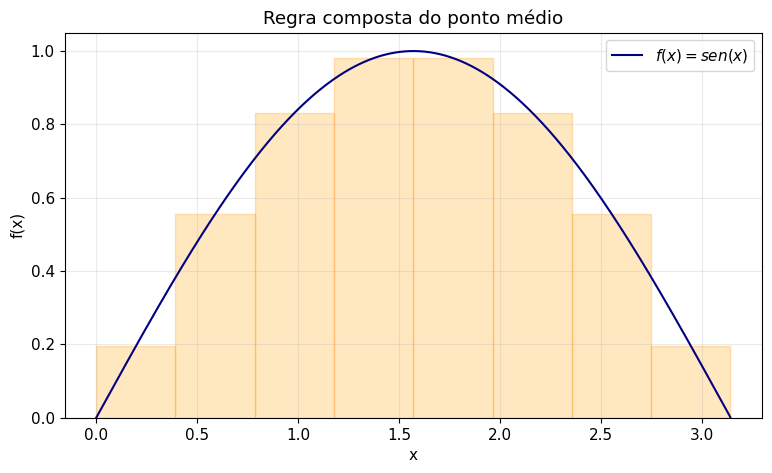

In [197]:
# Visualização dos retângulos do ponto médio
x = np.linspace(a, b, 500)
h = (b-a)/n
fig, ax = plt.subplots()
ax.plot(x, f(x), color="navy", label=r"$f(x)=sen(x)$")
for i in range(n):
    left = a + i*h
    mid = left + h/2
    ax.bar(mid, f(mid), width=h, align="center", alpha=0.25,
           edgecolor="darkorange", color="orange")
ax.set(xlabel="x", ylabel="f(x)", title="Regra composta do ponto médio")
ax.legend(); ax.grid(alpha=0.25); plt.show()


In [198]:
def trapezios(f, a, b, n):
    """Aproxima integral de f em [a,b] pela regra composta dos trapézios."""
    if n < 1:
        raise ValueError("n deve ser um inteiro positivo")
    x = np.linspace(a, b, n + 1)
    y = f(x)
    h = (b - a) / n
    return h * (0.5*y[0] + np.sum(y[1:-1]) + 0.5*y[-1])

print("Trapézios:", trapezios(f, a, b, n))


Trapézios: 1.974256537721767


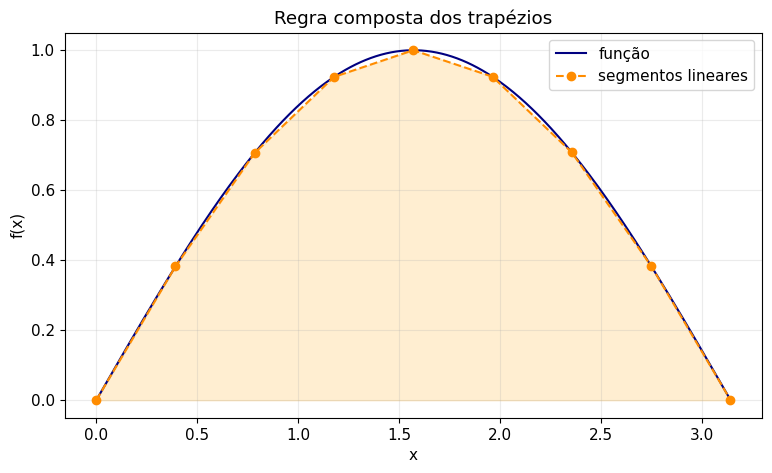

In [199]:
# Segmentos lineares usados pelos trapézios
x = np.linspace(a, b, 500)
xi = np.linspace(a, b, n+1)
fig, ax = plt.subplots()
ax.plot(x, f(x), color="navy", label="função")
ax.plot(xi, f(xi), "o--", color="darkorange", label="segmentos lineares")
ax.fill_between(xi, f(xi), alpha=0.18, color="orange")
ax.set(xlabel="x", ylabel="f(x)", title="Regra composta dos trapézios")
ax.legend(); ax.grid(alpha=0.25); plt.show()


In [200]:
def simpson(f, a, b, n):
    """Aproxima integral pela regra composta de Simpson 1/3 (n par)."""
    if n < 2 or n % 2 != 0:
        raise ValueError("Simpson 1/3 requer n par e n >= 2")
    x = np.linspace(a, b, n + 1)
    y = f(x)
    h = (b - a) / n
    return (h/3) * (y[0] + y[-1]
                    + 4*np.sum(y[1:-1:2])
                    + 2*np.sum(y[2:-1:2]))

print("Simpson:", simpson(f, a, b, n))



Simpson: 2.000267351019708


In [201]:
from scipy.integrate import quad

I_ref, erro_quad = quad(lambda x: np.exp(-x**2), 0, 1)
print(f"Referência (quad): {I_ref:.12f}")
print(f"Estimativa de erro do quad: {erro_quad:.2e}")

linhas = []
for n in [2, 4, 8, 16, 32, 64]:
    vals = {
        "n": n,
        "Ponto médio": ponto_medio(f, 0, 1, n),
        "Trapézios": trapezios(f, 0, 1, n),
        "Simpson": simpson(f, 0, 1, n),
    }
    for regra in ["Ponto médio", "Trapézios", "Simpson"]:
        vals["Erro " + regra] = abs(vals[regra] - I_ref)
    linhas.append(vals)

import pandas as pd
pd.DataFrame(linhas).set_index("n").style.format("{:.3e}")


Referência (quad): 0.746824132812
Estimativa de erro do quad: 8.29e-15


,Ponto médio,Trapézios,Simpson,Erro Ponto médio,Erro Trapézios,Erro Simpson
n,,,,,,
2,4.645e-01,4.501e-01,4.599e-01,2.823e-01,2.967e-01,2.870e-01
4,4.609e-01,4.573e-01,4.597e-01,2.859e-01,2.895e-01,2.871e-01
8,4.600e-01,4.591e-01,4.597e-01,2.868e-01,2.877e-01,2.871e-01
16,4.598e-01,4.595e-01,4.597e-01,2.871e-01,2.873e-01,2.871e-01
32,4.597e-01,4.597e-01,4.597e-01,2.871e-01,2.872e-01,2.871e-01
64,4.597e-01,4.597e-01,4.597e-01,2.871e-01,2.871e-01,2.871e-01


In [202]:
def ponto_medio(f, a, b, n):
    """Aproxima integral de f em [a,b] pela regra composta do ponto médio."""
    if n < 1:
        raise ValueError("n deve ser um inteiro positivo")
    h = (b - a) / n
    x_meio = a + (np.arange(n) + 0.5) * h
    return h * np.sum(f(x_meio))

# Exemplo: integral de exp(-x^2) entre 0 e 1
f = lambda x: np.sin(x)
a, b, n = 0.0, 3.14, 16
print("Aproximação pelo ponto médio:", ponto_medio(f, a, b, n))


Aproximação pelo ponto médio: 2.003211843885533


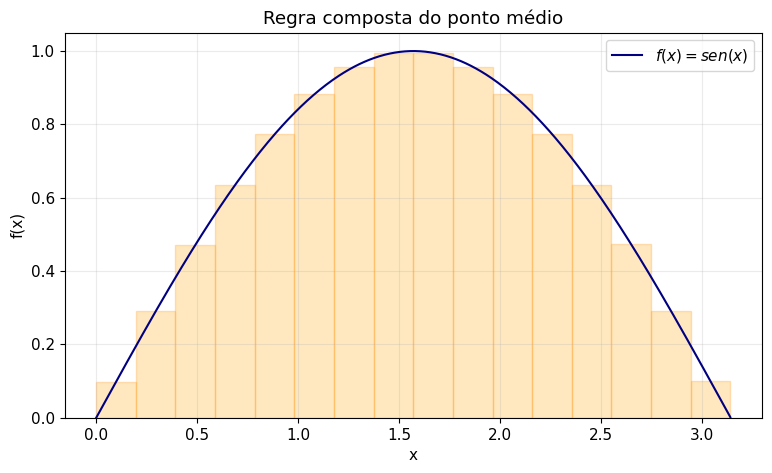

In [203]:
# Visualização dos retângulos do ponto médio
x = np.linspace(a, b, 500)
h = (b-a)/n
fig, ax = plt.subplots()
ax.plot(x, f(x), color="navy", label=r"$f(x)=sen(x)$")
for i in range(n):
    left = a + i*h
    mid = left + h/2
    ax.bar(mid, f(mid), width=h, align="center", alpha=0.25,
           edgecolor="darkorange", color="orange")
ax.set(xlabel="x", ylabel="f(x)", title="Regra composta do ponto médio")
ax.legend(); ax.grid(alpha=0.25); plt.show()


In [204]:
def trapezios(f, a, b, n):
    """Aproxima integral de f em [a,b] pela regra composta dos trapézios."""
    if n < 1:
        raise ValueError("n deve ser um inteiro positivo")
    x = np.linspace(a, b, n + 1)
    y = f(x)
    h = (b - a) / n
    return h * (0.5*y[0] + np.sum(y[1:-1]) + 0.5*y[-1])

print("Trapézios:", trapezios(f, a, b, n))


Trapézios: 1.9935756012325154


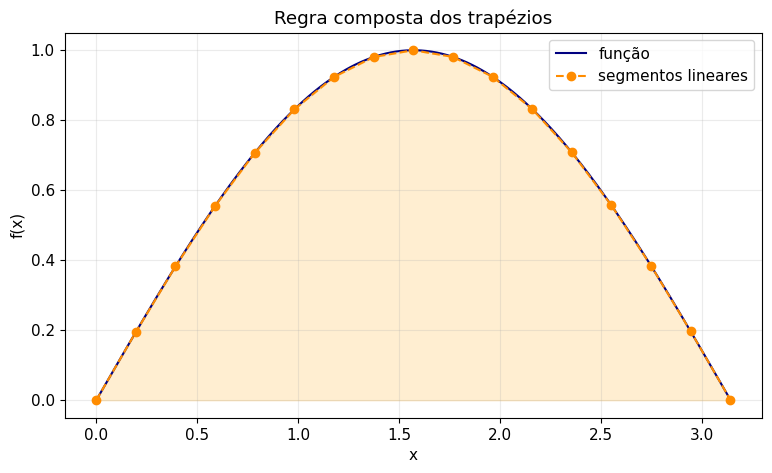

In [205]:
# Segmentos lineares usados pelos trapézios
x = np.linspace(a, b, 500)
xi = np.linspace(a, b, n+1)
fig, ax = plt.subplots()
ax.plot(x, f(x), color="navy", label="função")
ax.plot(xi, f(xi), "o--", color="darkorange", label="segmentos lineares")
ax.fill_between(xi, f(xi), alpha=0.18, color="orange")
ax.set(xlabel="x", ylabel="f(x)", title="Regra composta dos trapézios")
ax.legend(); ax.grid(alpha=0.25); plt.show()



In [206]:
def simpson(f, a, b, n):
    """Aproxima integral pela regra composta de Simpson 1/3 (n par)."""
    if n < 2 or n % 2 != 0:
        raise ValueError("Simpson 1/3 requer n par e n >= 2")
    x = np.linspace(a, b, n + 1)
    y = f(x)
    h = (b - a) / n
    return (h/3) * (y[0] + y[-1]
                    + 4*np.sum(y[1:-1:2])
                    + 2*np.sum(y[2:-1:2]))

print("Simpson:", simpson(f, a, b, n))



Simpson: 2.000015289069432


In [207]:
from scipy.integrate import quad

I_ref, erro_quad = quad(lambda x: np.exp(-x**2), 0, 1)
print(f"Referência (quad): {I_ref:.12f}")
print(f"Estimativa de erro do quad: {erro_quad:.2e}")

linhas = []
for n in [2, 4, 8, 16, 32, 64]:
    vals = {
        "n": n,
        "Ponto médio": ponto_medio(f, 0, 1, n),
        "Trapézios": trapezios(f, 0, 1, n),
        "Simpson": simpson(f, 0, 1, n),
    }
    for regra in ["Ponto médio", "Trapézios", "Simpson"]:
        vals["Erro " + regra] = abs(vals[regra] - I_ref)
    linhas.append(vals)

import pandas as pd
pd.DataFrame(linhas).set_index("n").style.format("{:.3e}")


Referência (quad): 0.746824132812
Estimativa de erro do quad: 8.29e-15


,Ponto médio,Trapézios,Simpson,Erro Ponto médio,Erro Trapézios,Erro Simpson
n,,,,,,
2,4.645e-01,4.501e-01,4.599e-01,2.823e-01,2.967e-01,2.870e-01
4,4.609e-01,4.573e-01,4.597e-01,2.859e-01,2.895e-01,2.871e-01
8,4.600e-01,4.591e-01,4.597e-01,2.868e-01,2.877e-01,2.871e-01
16,4.598e-01,4.595e-01,4.597e-01,2.871e-01,2.873e-01,2.871e-01
32,4.597e-01,4.597e-01,4.597e-01,2.871e-01,2.872e-01,2.871e-01
64,4.597e-01,4.597e-01,4.597e-01,2.871e-01,2.871e-01,2.871e-01


## 3. Regra dos trapézios

A regra dos trapézios é um método para aproximar a integral definida quando não queremos ou não conseguimos calcular seu valor exato. A ideia é substituir pequenos trechos da curva por segmentos de reta. Cada segmento, junto com o eixo horizontal, forma um trapézio.

### Como dividir o intervalo

Considere a integral

$$
\int_a^b f(x)\,dx.
$$

Primeiro, dividimos o intervalo $[a,b]$ em $n$ partes de mesma largura. A largura de cada parte é

$$
h=\frac{b-a}{n}.
$$

Os pontos que marcam essa divisão são

$$
x_i=a+ih,\qquad i=0,1,\ldots,n.
$$

Em cada subintervalo $[x_i,x_{i+1}]$, usamos os valores da função nos dois extremos, $f(x_i)$ e $f(x_{i+1})$, para construir um trapézio.

### Área de um trapézio

A área de um trapézio é calculada pela média das alturas multiplicada pela largura da base. Assim, no subintervalo $[x_i,x_{i+1}]$, a área aproximada é

$$
A_i\approx
\frac{f(x_i)+f(x_{i+1})}{2}\,h.
$$

Fazemos esse cálculo em todos os subintervalos e somamos as áreas. A regra composta dos trapézios é

$$
T_n
=
\frac{h}{2}
\sum_{i=0}^{n-1}
\left[f(x_i)+f(x_{i+1})\right].
$$

Reunindo os termos repetidos, obtemos a forma equivalente

$$
T_n
=
h\left[
\frac{f(x_0)+f(x_n)}{2}
+
\sum_{i=1}^{n-1}f(x_i)
\right].
$$

Nessa fórmula, os valores da função nos extremos do intervalo, $f(x_0)$ e $f(x_n)$, são multiplicados por $1/2$. Os valores nos pontos internos, $f(x_1),\ldots,f(x_{n-1})$, são somados com peso completo.

### Exemplo passo a passo

Vamos aproximar

$$
\int_0^2 x^2\,dx
$$

usando a regra dos trapézios com $n=2$ subintervalos.

**1. Calculamos a largura de cada subintervalo:**

$$
h=\frac{2-0}{2}=1.
$$

**2. Identificamos os pontos da divisão:**

$$
x_0=0,\qquad x_1=1,\qquad x_2=2.
$$

**3. Calculamos os valores da função $f(x)=x^2$ nesses pontos:**

$$
f(0)=0,\qquad f(1)=1,\qquad f(2)=4.
$$

**4. Substituímos os valores na fórmula:**

$$
T_2
=
1\left[
\frac{f(0)+f(2)}{2}+f(1)
\right].
$$

Portanto,

$$
T_2
=
1\left[
\frac{0+4}{2}+1
\right]
=3.
$$

Assim, a regra dos trapézios fornece a aproximação

$$
\int_0^2 x^2\,dx\approx 3.
$$

Para comparar, podemos calcular o valor exato:

$$
\int_0^2 x^2\,dx
=
\left[\frac{x^3}{3}\right]_0^2
=
\frac{8}{3}
\approx 2{,}667.
$$

A aproximação foi $3$, enquanto o valor exato é aproximadamente $2{,}667$. Portanto, neste exemplo, a regra dos trapézios **superestimou** a integral.

### Como interpretar o resultado geometricamente

Em cada subintervalo, o segmento de reta aproxima a curva. A área do trapézio pode ficar acima ou abaixo da área real sob a curva. Ao somar todos os trapézios, obtemos a aproximação da integral:

$$
\int_a^b f(x)\,dx\approx T_n.
$$

Se a função estiver acima do eixo $x$, as áreas contribuem positivamente. Se estiver abaixo do eixo $x$, elas contribuem negativamente, assim como ocorre na integral definida.

### Precisão e efeito do número de subintervalos

Para funções suficientemente suaves, o erro global da regra dos trapézios é da ordem de $h^2$. Isso significa que, em geral, diminuir $h$ melhora a aproximação.

Como $h=(b-a)/n$, aumentar $n$ reduz a largura dos subintervalos. Quando dobramos $n$, a largura $h$ é reduzida pela metade e o erro tende a diminuir aproximadamente por um fator de quatro. Esse comportamento é esperado quando a função é suave e a malha já é suficientemente fina.

### O que a curvatura pode indicar

A curvatura da função ajuda a prever o sentido do erro:

- Se $f''(x)>0$ em todo o intervalo, a função é convexa. Os segmentos de reta tendem a ficar acima da curva, e a regra dos trapézios tende a **superestimar** a integral.
- Se $f''(x)<0$ em todo o intervalo, a função é côncava. Os segmentos de reta tendem a ficar abaixo da curva, e a regra tende a **subestimar** a integral.

Essa previsão pressupõe que a função mantenha a mesma concavidade em todo o intervalo. Se a curvatura mudar, diferentes regiões podem contribuir para o erro em sentidos opostos.

### Em resumo

A regra dos trapézios aproxima a curva por segmentos de reta e soma as áreas dos trapézios formados. É simples de aplicar e funciona especialmente bem quando a função varia suavemente. Aumentar o número de subintervalos costuma melhorar a aproximação, mas a precisão também depende do comportamento da função.

In [208]:
def trapezios(f, a, b, n):
    """Aproxima integral de f em [a,b] pela regra composta dos trapézios."""
    if n < 1:
        raise ValueError("n deve ser um inteiro positivo")
    x = np.linspace(a, b, n + 1)
    y = f(x)
    h = (b - a) / n
    return h * (0.5*y[0] + np.sum(y[1:-1]) + 0.5*y[-1])

print("Trapézios:", trapezios(f, a, b, n))


Trapézios: 1.9995975277348


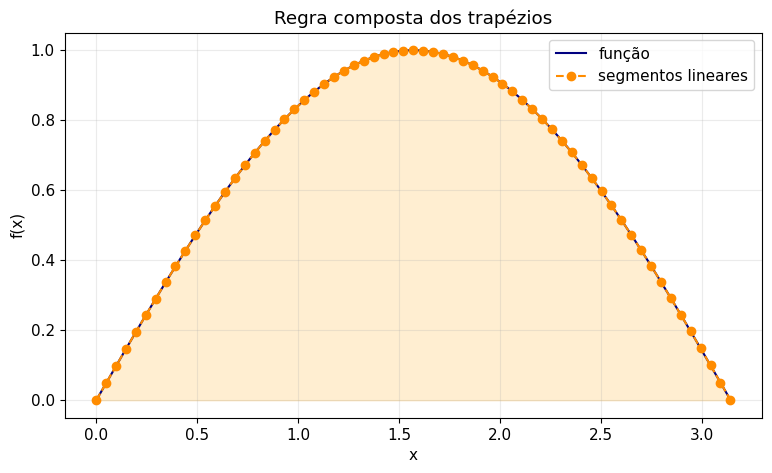

In [209]:
# Segmentos lineares usados pelos trapézios
x = np.linspace(a, b, 500)
xi = np.linspace(a, b, n+1)
fig, ax = plt.subplots()
ax.plot(x, f(x), color="navy", label="função")
ax.plot(xi, f(xi), "o--", color="darkorange", label="segmentos lineares")
ax.fill_between(xi, f(xi), alpha=0.18, color="orange")
ax.set(xlabel="x", ylabel="f(x)", title="Regra composta dos trapézios")
ax.legend(); ax.grid(alpha=0.25); plt.show()


## 4. Regra de Simpson 1/3

A regra de Simpson 1/3 é uma técnica para aproximar uma integral definida. Sua ideia é aproximar a curva por parábolas e, em seguida, calcular a área sob essas parábolas.

Na regra dos trapézios, cada trecho da curva é aproximado por uma reta. Simpson usa uma parábola, que pode representar melhor a curvatura da função. Para construir cada parábola, usamos três pontos consecutivos: o início, o ponto médio e o fim de um trecho.

### 4.1 Como dividir o intervalo

Considere a integral

$$
\int_a^b f(x)\,dx.
$$

Dividimos o intervalo $[a,b]$ em $n$ subintervalos de mesma largura. A largura de cada subintervalo é

$$
h=\frac{b-a}{n}.
$$

Os pontos da divisão são

$$
x_i=a+ih,\qquad i=0,1,\ldots,n.
$$

A regra de Simpson trabalha com **dois subintervalos por vez**. Para cada grupo, usamos três pontos para ajustar uma parábola:

$$
x_0,\quad x_1,\quad x_2.
$$

Por esse motivo, o número total de subintervalos, $n$, precisa ser **par**.

Por exemplo, se $n=4$, os pontos são $x_0,x_1,x_2,x_3,x_4$. Podemos formar dois grupos:

$$
(x_0,x_1,x_2)
\qquad\text{e}\qquad
(x_2,x_3,x_4).
$$

Cada grupo define uma parábola. O ponto $x_2$ é compartilhado pelos dois grupos.

### 4.2 Fórmula para um grupo de dois subintervalos

Para aproximar a integral em um grupo formado pelos pontos $x_0$, $x_1$ e $x_2$, usamos:

$$
\int_{x_0}^{x_2} f(x)\,dx
\approx
\frac{h}{3}
\left[
f(x_0)+4f(x_1)+f(x_2)
\right].
$$

O ponto central recebe peso $4$, enquanto os pontos das extremidades recebem peso $1$. Esses pesos vêm da fórmula de integração da parábola que passa pelos três pontos.

### 4.3 Fórmula composta

Quando o intervalo tem mais de dois subintervalos, aplicamos a fórmula em cada grupo de dois subintervalos e somamos as aproximações. O resultado é a regra composta de Simpson 1/3:

$$
S_n
=
\frac{h}{3}
\left[
f(x_0)+f(x_n)
+
4\sum_{\substack{i=1\\ i\text{ ímpar}}}^{n-1} f(x_i)
+
2\sum_{\substack{i=2\\ i\text{ par}}}^{n-2} f(x_i)
\right].
$$

Os pesos seguem o padrão

$$
1,\ 4,\ 2,\ 4,\ 2,\ \ldots,\ 4,\ 1.
$$

Isso significa que:

- os valores nos extremos, $f(x_0)$ e $f(x_n)$, recebem peso $1$;
- os valores nos índices ímpares recebem peso $4$;
- os valores internos nos índices pares recebem peso $2$.

Depois de multiplicar a soma ponderada por $h/3$, obtemos a aproximação da integral:

$$
\int_a^b f(x)\,dx\approx S_n.
$$

### 4.4 Exemplo passo a passo

Vamos aproximar

$$
\int_0^2 x^3\,dx
$$

usando $n=2$ subintervalos.

**Passo 1 — Calcular a largura dos subintervalos**

$$
h=\frac{b-a}{n}
=\frac{2-0}{2}
=1.
$$

**Passo 2 — Identificar os pontos**

Como o intervalo começa em $0$ e cada passo tem largura $1$, temos:

$$
x_0=0,\qquad x_1=1,\qquad x_2=2.
$$

**Passo 3 — Calcular os valores da função**

Para $f(x)=x^3$:

$$
f(x_0)=f(0)=0,
\qquad
f(x_1)=f(1)=1,
\qquad
f(x_2)=f(2)=8.
$$

**Passo 4 — Aplicar a fórmula**

Como temos um único grupo de dois subintervalos:

$$
S_2
=
\frac{h}{3}
\left[
f(x_0)+4f(x_1)+f(x_2)
\right].
$$

Substituindo $h=1$ e os valores da função:

$$
S_2
=
\frac{1}{3}
\left[
0+4(1)+8
\right]
=
\frac{12}{3}
=
4.
$$

Assim, a regra de Simpson fornece

$$
\int_0^2 x^3\,dx\approx 4.
$$

Neste exemplo, a aproximação coincide com o valor exato:

$$
\int_0^2 x^3\,dx
=
\left[\frac{x^4}{4}\right]_0^2
=
4.
$$

### 4.5 Quando Simpson fornece um resultado exato?

A regra de Simpson 1/3 integra exatamente polinômios de grau até 3, desde que os cálculos sejam feitos sem erros de arredondamento. Isso inclui funções como

$$
f(x)=1,\qquad f(x)=x,\qquad f(x)=x^2,\qquad f(x)=x^3.
$$

Para outras funções, o resultado geralmente é uma aproximação. Ainda assim, Simpson costuma apresentar boa precisão quando a função varia suavemente.

### 4.6 Precisão e erro

Para funções com derivadas contínuas até a quarta ordem, o erro global da regra composta de Simpson é da ordem de $h^4$. Em termos simples, isso indica que o erro tende a diminuir rapidamente quando reduzimos o tamanho dos subintervalos.

Se dobrarmos o número de subintervalos, $n$, a largura $h$ será reduzida pela metade. Em condições adequadas, o erro de Simpson tende a ficar aproximadamente $16$ vezes menor, pois

$$
\left(\frac{h}{2}\right)^4=\frac{h^4}{16}.
$$

Esse fator é uma tendência teórica, válida quando a função é suficientemente suave e a malha está em uma faixa adequada. Descontinuidades, oscilações ou ruído nos dados podem alterar o comportamento observado.

### Para lembrar

- Simpson aproxima a curva por parábolas.
- Cada parábola é ajustada usando três pontos consecutivos.
- Cada grupo cobre dois subintervalos; por isso, $n$ deve ser par.
- Os pesos da fórmula seguem o padrão $1,4,2,4,\ldots,2,4,1$.
- A regra é exata para polinômios de grau até 3.
- Para funções suaves, o erro global é da ordem de $h^4$.

In [210]:
def simpson(f, a, b, n):
    """Aproxima integral pela regra composta de Simpson 1/3 (n par)."""
    if n < 2 or n % 2 != 0:
        raise ValueError("Simpson 1/3 requer n par e n >= 2")
    x = np.linspace(a, b, n + 1)
    y = f(x)
    h = (b - a) / n
    return (h/3) * (y[0] + y[-1]
                    + 4*np.sum(y[1:-1:2])
                    + 2*np.sum(y[2:-1:2]))

print("Simpson:", simpson(f, a, b, n))


Simpson: 1.999998796126725


### Por que Simpson exige um número par de subintervalos?

A parábola é ajustada usando três nós consecutivos: início, ponto médio e fim de um bloco. Cada bloco cobre dois subintervalos. Assim, os subintervalos precisam ser agrupados em pares. Se houver um número ímpar de subintervalos, a implementação acima interrompe o cálculo para evitar aplicar uma fórmula incompatível.


## 5. Comparação das regras em um exemplo

Para \(f(x)=e^{-x^2}\) em \([0,1]\), não precisamos conhecer uma antiderivada elementar. `scipy.integrate.quad` será usado apenas como valor de referência de alta precisão; as três regras implementadas são independentes do SciPy.


In [211]:
from scipy.integrate import quad

I_ref, erro_quad = quad(lambda x: np.exp(-x**2), 0, 1)
print(f"Referência (quad): {I_ref:.12f}")
print(f"Estimativa de erro do quad: {erro_quad:.2e}")

linhas = []
for n in [2, 4, 8, 16, 32, 64]:
    vals = {
        "n": n,
        "Ponto médio": ponto_medio(f, 0, 1, n),
        "Trapézios": trapezios(f, 0, 1, n),
        "Simpson": simpson(f, 0, 1, n),
    }
    for regra in ["Ponto médio", "Trapézios", "Simpson"]:
        vals["Erro " + regra] = abs(vals[regra] - I_ref)
    linhas.append(vals)

import pandas as pd
pd.DataFrame(linhas).set_index("n").style.format("{:.3e}")


Referência (quad): 0.746824132812
Estimativa de erro do quad: 8.29e-15


,Ponto médio,Trapézios,Simpson,Erro Ponto médio,Erro Trapézios,Erro Simpson
n,,,,,,
2,4.645e-01,4.501e-01,4.599e-01,2.823e-01,2.967e-01,2.870e-01
4,4.609e-01,4.573e-01,4.597e-01,2.859e-01,2.895e-01,2.871e-01
8,4.600e-01,4.591e-01,4.597e-01,2.868e-01,2.877e-01,2.871e-01
16,4.598e-01,4.595e-01,4.597e-01,2.871e-01,2.873e-01,2.871e-01
32,4.597e-01,4.597e-01,4.597e-01,2.871e-01,2.872e-01,2.871e-01
64,4.597e-01,4.597e-01,4.597e-01,2.871e-01,2.871e-01,2.871e-01


## 6. Visualização da convergência


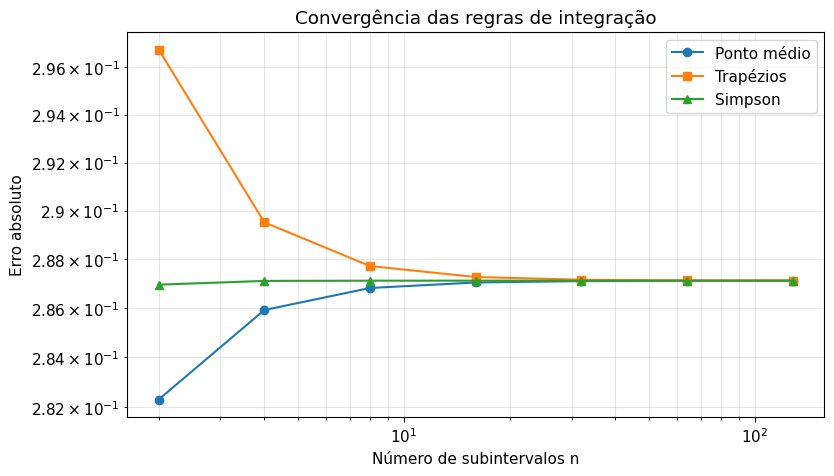

In [212]:
ns = np.array([2, 4, 8, 16, 32, 64, 128])
err_m = np.array([abs(ponto_medio(f, 0, 1, int(k))-I_ref) for k in ns])
err_t = np.array([abs(trapezios(f, 0, 1, int(k))-I_ref) for k in ns])
err_s = np.array([abs(simpson(f, 0, 1, int(k))-I_ref) for k in ns])

plt.loglog(ns, err_m, "o-", label="Ponto médio")
plt.loglog(ns, err_t, "s-", label="Trapézios")
plt.loglog(ns, err_s, "^-", label="Simpson")
plt.xlabel("Número de subintervalos n")
plt.ylabel("Erro absoluto")
plt.title("Convergência das regras de integração")
plt.grid(True, which="both", alpha=0.3); plt.legend(); plt.show()


## 7. Estimativa de erro por refinamento (Richardson)

Se uma aproximação tem erro dominante proporcional a \(h^p\), então refinar a malha (usar \(2n\) subintervalos) permite estimar o erro da aproximação mais fina por

$$
|I-I_{2n}|\approx \frac{|I_{2n}-I_n|}{2^p-1}.
$$

Use \(p=2\) para ponto médio e trapézios e \(p=4\) para Simpson, desde que a função seja suave e estejamos na região assintótica. É uma estimativa prática, não um limite rigoroso universal.


In [213]:
def estimativa_richardson(valor_n, valor_2n, ordem):
    return abs(valor_2n - valor_n) / (2**ordem - 1)

n = 8
for nome, regra, p in [("Ponto médio", ponto_medio, 2),
                       ("Trapézios", trapezios, 2),
                       ("Simpson", simpson, 4)]:
    I_n = regra(f, 0, 1, n)
    I_2n = regra(f, 0, 1, 2*n)
    erro_estimado = estimativa_richardson(I_n, I_2n, p)
    erro_real = abs(I_2n - I_ref)
    print(f"{nome:12s}: estimado={erro_estimado:.3e} | real da malha 2n={erro_real:.3e}")


Ponto médio : estimado=7.486e-05 | real da malha 2n=2.871e-01
Trapézios   : estimado=1.497e-04 | real da malha 2n=2.873e-01
Simpson     : estimado=3.905e-08 | real da malha 2n=2.871e-01


## 8. Exemplo com integral conhecida

Vamos integrar \(f(x)=x^3\) em \([0,2]\). O valor exato é

$$
\int_0^2 x^3\,dx=\left.\frac{x^4}{4}\right|_0^2=4.
$$

Simpson deve recuperar esse valor (a menos de arredondamento), pois a função é um polinômio de grau 3.


In [214]:
g = lambda x: x**3
I_exato = 4.0
for nome, regra, n_teste in [("Ponto médio", ponto_medio, 8),
                             ("Trapézios", trapezios, 8),
                             ("Simpson", simpson, 8)]:
    aproxima = regra(g, 0, 2, n_teste)
    print(f"{nome:12s}: {aproxima:.12f} | erro = {abs(aproxima-I_exato):.3e}")


Ponto médio : 3.968750000000 | erro = 3.125e-02
Trapézios   : 4.062500000000 | erro = 6.250e-02
Simpson     : 4.000000000000 | erro = 0.000e+00


## 9. Integração a partir de dados tabelados

Às vezes não temos uma fórmula para \(f\), apenas medições $((x_i,y_i))$. Para malha uniforme, podemos aplicar trapézios ou Simpson diretamente aos dados. Simpson requer número par de subintervalos.

Deslocamento aproximado (trapézios): 8.4500 m


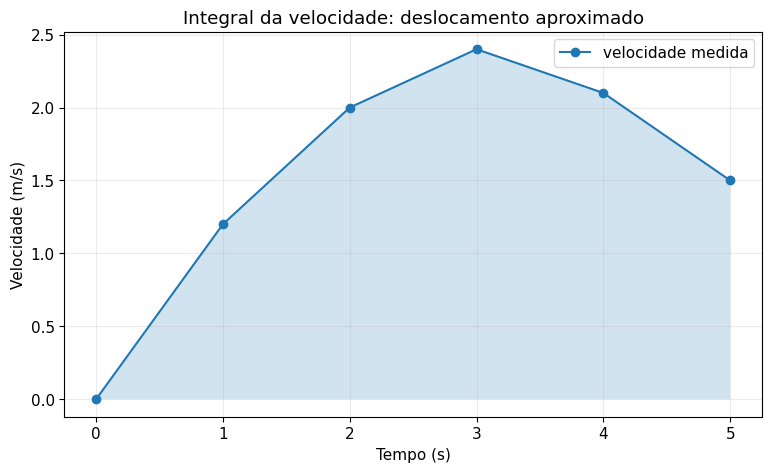

In [215]:
# Exemplo de medições (valores sintéticos): velocidade ao longo do tempo
x_dados = np.array([0, 1, 2, 3, 4, 5], dtype=float)
v_dados = np.array([0.0, 1.2, 2.0, 2.4, 2.1, 1.5])

# Trapézios em dados igualmente espaçados
deslocamento_trap = np.trapezoid(v_dados, x_dados)
print(f"Deslocamento aproximado (trapézios): {deslocamento_trap:.4f} m")

# Visualização das medições
plt.plot(x_dados, v_dados, "o-", label="velocidade medida")
plt.fill_between(x_dados, v_dados, alpha=0.2)
plt.xlabel("Tempo (s)"); plt.ylabel("Velocidade (m/s)")
plt.title("Integral da velocidade: deslocamento aproximado")
plt.grid(alpha=0.25); plt.legend(); plt.show()


## 10. Cuidados práticos

- **Escolha da regra:** Simpson costuma ser eficiente para funções suaves; trapézios é simples e funciona diretamente com dados tabelados.
- **Número de subintervalos:** Simpson 1/3 requer \(n\) par.
- **Regularidade:** descontinuidades, quinas e oscilações podem reduzir a ordem esperada de convergência.
- **Dados experimentais:** ruído nas medições não desaparece só porque usamos mais pontos; considere incerteza e resolução do instrumento.
- **Arredondamento:** aumentar \(n\) indefinidamente pode fazer erros de arredondamento se tornarem relevantes.
- **Unidades:** se \(f\) tem unidade de m/s e \(x\) está em s, a integral tem unidade de m.
- **Sinal:** uma integral pode ser negativa; não confundir integral assinada com área geométrica total.


## 11. Atividade guiada

Considere duas funções senoidais distintas e calcule:

1. Calcule a integral exata manualmente.
2. Aproxime usando as três regras para \(n=2,4,8,16\).
3. Monte uma tabela de erros absolutos.
4. Faça um gráfico do erro em função de \(n\), com escala log-log.
5. Compare o comportamento observado com as ordens teóricas.
6. Explique qual regra foi mais eficiente neste exemplo e por quê.


In [216]:
def ponto_medio(f, a, b, n):
    """Aproxima integral de f em [a,b] pela regra composta do ponto médio."""
    if n < 1:
        raise ValueError("n deve ser um inteiro positivo")
    h = (b - a) / n
    x_meio = a + (np.arange(n) + 0.5) * h
    return h * np.sum(f(x_meio))

# Exemplo: integral de exp(-x^2) entre 0 e 1
f = lambda x: np.exp(-x**2)
a, b, n = 0.0, 1.0, 4
print("Aproximação pelo ponto médio:", ponto_medio(f, a, b, n))


Aproximação pelo ponto médio: 0.7487471318910093


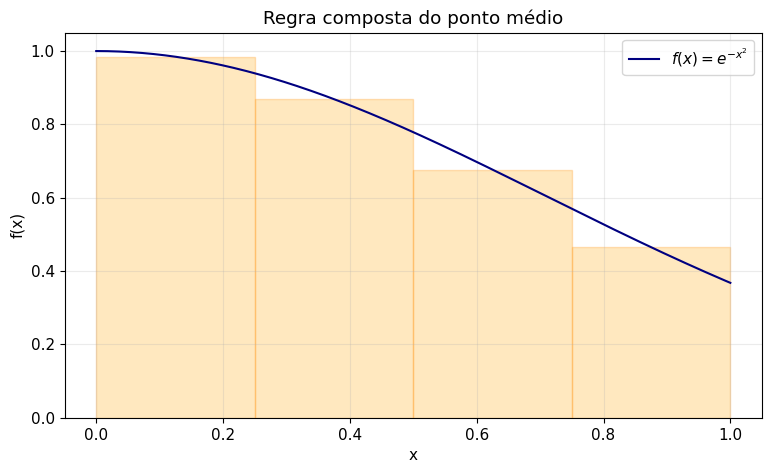

In [217]:
# Visualização dos retângulos do ponto médio
x = np.linspace(a, b, 500)
h = (b-a)/n
fig, ax = plt.subplots()
ax.plot(x, f(x), color="navy", label=r"$f(x)=e^{-x^2}$")
for i in range(n):
    left = a + i*h
    mid = left + h/2
    ax.bar(mid, f(mid), width=h, align="center", alpha=0.25,
           edgecolor="darkorange", color="orange")
ax.set(xlabel="x", ylabel="f(x)", title="Regra composta do ponto médio")
ax.legend(); ax.grid(alpha=0.25); plt.show()


In [218]:
# Comece o exercício aqui; use células adicionais para responder.
f_atividade = lambda x: np.sin(x)
a_atividade, b_atividade = 0.0, np.pi
I_atividade_exata = 2.0

for n in [2, 4, 8, 16]:
    print(n,
          "M=", ponto_medio(f_atividade, a_atividade, b_atividade, n),
          "T=", trapezios(f_atividade, a_atividade, b_atividade, n),
          "S=", simpson(f_atividade, a_atividade, b_atividade, n))


2 M= 2.221441469079183 T= 1.5707963267948966 S= 2.0943951023931953
4 M= 2.0523443059540623 T= 1.8961188979370398 S= 2.0045597549844207
8 M= 2.012909085599128 T= 1.9742316019455508 S= 2.0002691699483877
16 M= 2.00321637816795 T= 1.9935703437723395 S= 2.0000165910479355
